# Spearman-féle rangkorreláció

Olyan statisztikai mérőszám, amely két rangsorolt ​​változó közötti kapcsolat erősségének és irányának meghatározására szolgál. Azt vizsgálja, hogy két változó közötti kapcsolat mennyire jól írható le monoton függvény segítségével.

- Rangok alapján működik, nem pedig tényleges értékek alapján
- Akkor használják, **ha az adatok nem normális eloszlásúak**
- Sorszámadatokhoz alkalmas
- Monoton kapcsolatokat mér, nem csak lineárisakat

## Matematikai intuíció
A Spearman-féle rangkorreláció, amelyet **ρ-vel (rho) jelölünk**, **két változó közötti kapcsolat erősségét és irányát méri a rangjuk alapján**, nem pedig a tényleges értékek alapján. Az értékek -1 és +1 között mozognak.

- +1: tökéletes pozitív monoton kapcsolat, azaz ha az egyik változó növekszik a másik növekedésével
- -1: tökéletes negatív monoton kapcsolat, azaz ha az egyik növekszik, míg a másik csökken
- 0: nincs monoton kapcsolat


A monoton kapcsolat olyan kapcsolatot jelent, amelyben a változók csak egy irányba mozognak.

$$\rho = 1 - \frac{6 \sum d^2}{n(n^2 - 1)}$$

- d: a megfelelő értékek rangjai közötti különbség
- n: a megfigyelések teljes száma

## Mikor használjuk a Spearman-féle rangkorrelációt?
- Nemlineáris adatokkal működik
- Az adatok monoton trendet követnek
- A változók rangokat vagy pontszámokat tartalmaznak
- Nem feltételez normális eloszlást
- Sorszámos adatokat kezel
- Az adathalmaz kiugró értékeket tartalmaz


## Spearman rangkorrelációjának kiszámítása

### 1. Eredeti adatok

|No.|X1|Y1|
|:---|:--|:--|
|1|7|5|
|2|6|4|
|3|4|5|
|4|5|6|
|5|8|10|
|6|7|7|
|7|10|9|
|8|3|2|
|9|9|8|
|10|2|1|

### 2. Adatok rangsorolása

A rangsorokat az értékek növekvő sorrendbe rendezésével határozzuk meg. Ha az értékek egyenlőek, akkor az átlagos rangsor kerül meghatározásra.

- Ranking X1 :
    - Rendezett X1 értékek:2, 3, 4, 5, 6, 7, 7, 8, 9, 10
    - A két érték, a 7 és a 7, holtversenyben van → mindkettő 6,5-ös rangot kap

- Ranking Y1 :
    - A rangokat ugyanazzal a módszerrel osztják ki.
    - Rendezett Y1 értékek: 1, 2, 4, 5, 5, 6, 7, 8, 9, 10
    - Az 5-ös és 5-ös értékek holtversenyben vannak, azaz mindkettő átlagosan 4,5-ös rangsorolást kap.

### 3. Rangsorolja a táblázatot a különbségekkel
|No.|Rank X1| Rank Y1| d| $$d^2$$|
|:---|:--|:--|:--|:--|
|1|6.5 |4.5|2|4|
|2|5|3|2|4|
|3|3|4.5|-1.5|	2.25|
|4|4|6|-2|	4|
|5|8|10|-2|4|
|6|6.5|7|-0.5|0.25|
|7|10|9|1|1|
|8|2|2|0|0|
|9|9|8|1|1|
|10|1|1|0|0|


$\sum d^2 = 20,5$

### 4. Behelyettesítés a képletbe:

$$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$ $$\rho = 1 - \frac{6 \times 20,5}{10(10^2 - 1)}$$  $$\rho = 1 - 0,12424$$   $$\rho \approx 0,88$$

> Ez erős pozitív monoton kapcsolatot jelez


## Spearman rangkorrelációjának kiszámítása Pythonban

Mintaadatok

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = {
    'Hours_Studied': [2, 4, 6, 8, 10],
    'Marks': [50, 55, 65, 70, 90]
}

df = pd.DataFrame(data)
df

,Hours_Studied,Marks
0,2,50
1,4,55
2,6,65
3,8,70
4,10,90


In [ ]:
# Spearman-korreláció alkalmazása
spearman_corr = df['Hours_Studied'].corr(df['Marks'], method='spearman')
print("Spearman Correlation:", spearman_corr)



Spearman Correlation: 0.9999999999999999


> Az adatok tökéletesen növekvő rangsorrendet mutatnak. Ezért a korrelációs érték 0,9.

A Spearman-korreláció vizualizálása

- A hőtérkép csak a kiválasztott oszlopok közötti korrelációt jeleníti meg
- Segít vizuálisan megerősíteni a kapcsolat erősségét

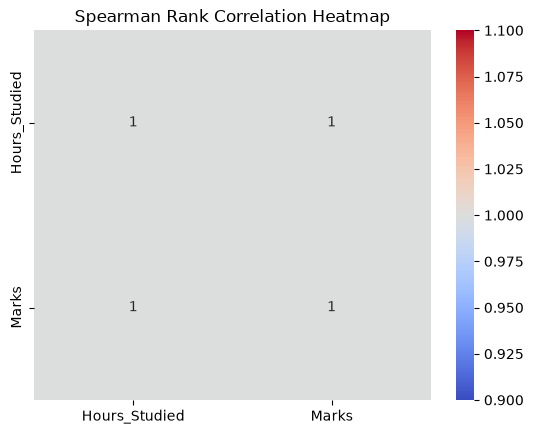

In [6]:
corr_data = df[['Hours_Studied', 'Marks']].corr(method='spearman')

sns.heatmap(corr_data, annot=True, cmap='coolwarm')
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

Szórásdiagram monoton kapcsolat esetén

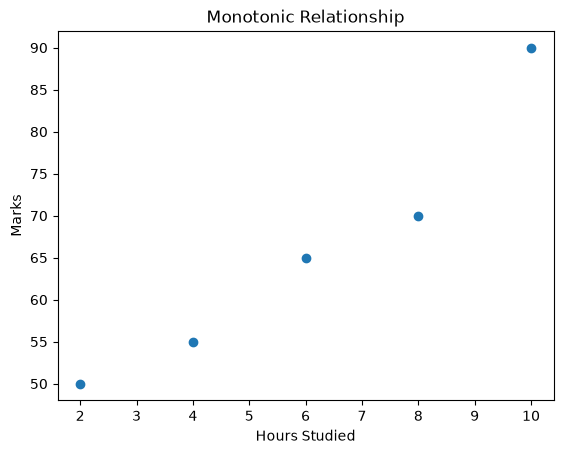

In [7]:
plt.scatter(df['Hours_Studied'], df['Marks'])
plt.xlabel("Hours Studied")
plt.ylabel("Marks")
plt.title("Monotonic Relationship")
plt.show()

A szóródási diagram konzisztens emelkedő trendet mutat, ami megerősíti a monoton kapcsolatot.

## Különbség a Pearson és a Spearman korreláció között

Nézzük meg a Pearson-korreláció és a Spearman-korreláció közötti különbségeket:

|Megjelenítés|Pearson-korreláció|Spearman-korreláció|
|:---|:--|:--|
|**Adattípus**|Folyamatos|Sorszám vagy folyamatos|
|**Valós értékeket használ**|Igen|Nem|
|**Rangsorokat használ**|Nem|Igen|
|**Normális eloszlást feltételez**|Igen|Nem|
|**Kapcsolat típusa**|Lineáris|Monoton|


**Előnyök**

- Nemlineáris monoton adatokkal működik
- Kevésbé befolyásolják a kiugró értékek
- Egyszerűen kiszámítható és értelmezhető
- Nincsenek szigorú eloszlási feltételezések

**Korlátozások**

- Figyelmen kívül hagyja a tényleges adatértékeket
- Nem képes nem monoton mintázatokat észlelni
- Kevésbé informatív a pontos numerikus összefüggések szempontjából
- Kevésbé pontos nagyon kis adathalmazok esetén

**Alkalmazások**

- A diákok rangsorolása az osztályzatok alapján
- A keresési találatok rangsorolásának összehasonlítása
- Az ügyfél-elégedettségi szint mérése
- Viselkedés- és társadalomtudományi tanulmányok
-  Felmérési adatok elemzése
- Funkciórangsorolás gépi tanulásban
- Orvosi és társadalomtudományi tanulmányok